In [1]:
# Import and doing some tests
import numpy as np
import matplotlib.pyplot as plt
from lib import Portfolio

Ploting libs

In [2]:
def make_plots(N,time, u_star_zero, u_star_expo, u_star_power,X_star_zero,X_star_expo,X_star_power,figsize=(9,6),loc="lower center",how="all"):
    assert how in ["all","inventory"], "Accepted fields:'all','how'"
    if how=="all":
        fig, ax = plt.subplots(nrows=N, ncols=2, figsize=figsize) 
    else:
        fig, ax = plt.subplots(nrows=1, ncols=N, figsize=figsize) 

    fig.subplots_adjust(wspace=0.3, hspace=0.4)
    for i in range(N):
        if how=="all":
            ax[i,0].plot( time[:-1:], u_star_zero[:-1:,i], label="no transient",color='#1f77b4' )
            ax[i,0].plot( time[:-1:], u_star_expo[:-1:,i], label="exponetial",color='orange' )
            ax[i,0].plot( time[:-1:], u_star_power[:-1:,i], label="fractional",color='green' )
            ax[i,0].title.set_text(f'Asset {i+1}: Optimal trading speed')
            ax[i,0].legend(loc=loc)

            ax[i,1].plot( time, X_star_zero[:,i], label="no transient",color='#1f77b4' )
            ax[i,1].plot( time, X_star_expo[:,i], label="exponetial",color='orange' )
            ax[i,1].plot( time, X_star_power[:,i], label="fractional",color='green' )
            ax[i,1].title.set_text(f'Asset {i+1}: Running inventory')
            ax[i,1].legend(loc=loc)
        elif how=="inventory":
            ax[i].plot( time, X_star_zero[:,i], label="no transient",color='#1f77b4' )
            ax[i].plot( time, X_star_expo[:,i], label="exponetial",color='orange' )
            ax[i].plot( time, X_star_power[:,i], label="fractional",color='green' )
            ax[i].title.set_text(f'Asset {i+1}: Running inventory')
            ax[i].legend(loc=loc)
    return fig, ax

def make_plots2(N,time, X_star_zero,X_star_power, X_star_power_cross, I,figsize=(12,5)):
    fig, ax = plt.subplots(nrows=1, ncols=N, figsize=figsize)
    fig.subplots_adjust(wspace=0.3, hspace=0.4)
    for i in range(N):
        ax[i].plot( time, X_star_zero[:,i], label="no transient", color='#1f77b4' )
        ax[i].plot( time, X_star_power[:,i], label="fractional without cross impact", color='green' )
        ax[i].plot( time, X_star_power_cross[:,i], '--',label="fractional with cross impact", color='green' )
        ax[i].plot( time[:-1:], np.cumsum(I,axis=0)[:,i]*dt, label=r"Signal $\sum_{k=0}^{t}I_k \Delta t$", color='red')
        ax[i].title.set_text(f'Asset {i+1}: Running inventory')
        ax[i].legend(loc='upper right')

    return fig, ax


def simulate_I_deterministic(n, N, I0, beta, dt):
    from scipy.linalg import expm
    I0   = np.asarray(I0, float)
    t    = np.arange(n) * dt         
    I    = np.zeros((n, N))
    for k in range(n):
        I[k] = expm(-beta * t[k]) @ I0
    return I

### I. Cross Impact Influence <br/>


Experiment 1

In [3]:
# Inputs
T=10
N=2
n=1000
dt = T/n
X0 = np.array([10,0])
I_t = np.zeros((n,N))
E_dA = I_t*dt
Lambda = np.diag([0.03,0.03])
gamma = 0
Sigma = np.array([[1,0],[0,1]])
varrho = 4
C = np.diag([0.06,0.06])
Pi = np.eye(N)
alpha, rho = 0.25, 0.5
ptf = Portfolio(N=N, T=T, n=n)

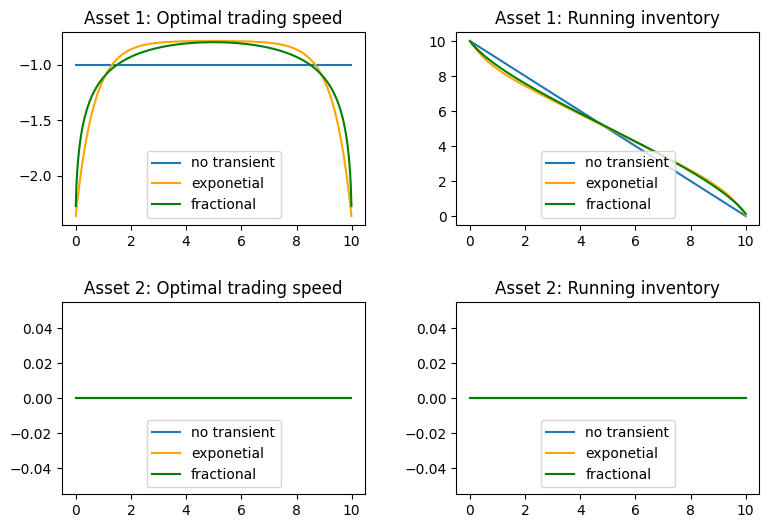

In [4]:
u_star_zero, X_star_zero  = ptf.build_optimal(
                    X0=X0,
                    E_dA=E_dA,
                    Lambda=Lambda,
                    Sigma=Sigma, 
                    gamma=gamma,
                    C=C,
                    varrho=varrho,
                    Pi = Pi,
                    kernel="zero"
                    )

u_star_power, X_star_power  = ptf.build_optimal(
                    X0=X0,
                    E_dA=E_dA,
                    Lambda=Lambda,
                    Sigma=Sigma, 
                    gamma=gamma,
                    C=C,
                    varrho=varrho,
                    Pi = Pi,
                    kernel="power-law",
                    kernel_scale=alpha,
                    )

u_star_expo, X_star_expo  = ptf.build_optimal(
                    X0=X0,
                    E_dA=E_dA,
                    Lambda=Lambda,
                    Sigma=Sigma, 
                    gamma=gamma,
                    C=C,
                    varrho=varrho,
                    Pi = Pi,
                    kernel="exponential",
                    kernel_scale=rho,
                    )

make_plots(N,ptf.times, u_star_zero, u_star_expo, u_star_power, X_star_zero,X_star_expo,X_star_power)
plt.show()

Experiment 2

In [5]:
# Inputs
C = np.array( [[0.06,0.05],[0.05,0.06]] )

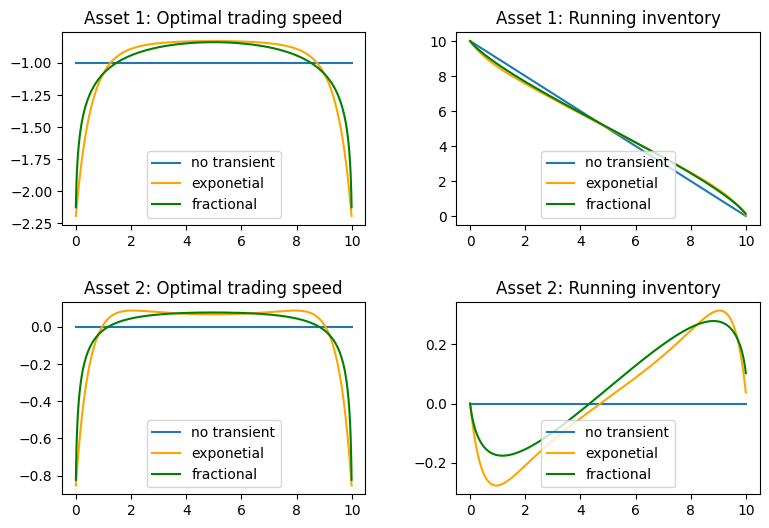

In [6]:
u_star_zero, X_star_zero  = ptf.build_optimal(
                    X0=X0,
                    E_dA=E_dA,
                    Lambda=Lambda,
                    Sigma=Sigma, 
                    gamma=gamma,
                    C=C,
                    varrho=varrho,
                    Pi = Pi,
                    kernel="zero"
                    )

u_star_power, X_star_power  = ptf.build_optimal(
                    X0=X0,
                    E_dA=E_dA,
                    Lambda=Lambda,
                    Sigma=Sigma, 
                    gamma=gamma,
                    C=C,
                    varrho=varrho,
                    Pi = Pi,
                    kernel="power-law",
                    kernel_scale=alpha,
                    )

u_star_expo, X_star_expo  = ptf.build_optimal(
                    X0=X0,
                    E_dA=E_dA,
                    Lambda=Lambda,
                    Sigma=Sigma, 
                    gamma=gamma,
                    C=C,
                    varrho=varrho,
                    Pi = Pi,
                    kernel="exponential",
                    kernel_scale=rho,
                    )

make_plots(N,ptf.times, u_star_zero, u_star_expo, u_star_power, X_star_zero,X_star_expo,X_star_power)
plt.show()

Experiment 3

In [7]:
#Inputs
I0 = np.array([0.5,0.5])
beta_1, beta_2 = 0.9, 0.3
beta = np.diag([beta_1,beta_2])
I_t = simulate_I_deterministic(n,N,I0, beta, dt)
E_dA = I_t*dt
C = np.diag([0.06,0.06])
C_crosseffect  = np.array([[0.06, 0.05], [0.05, 0.06]])

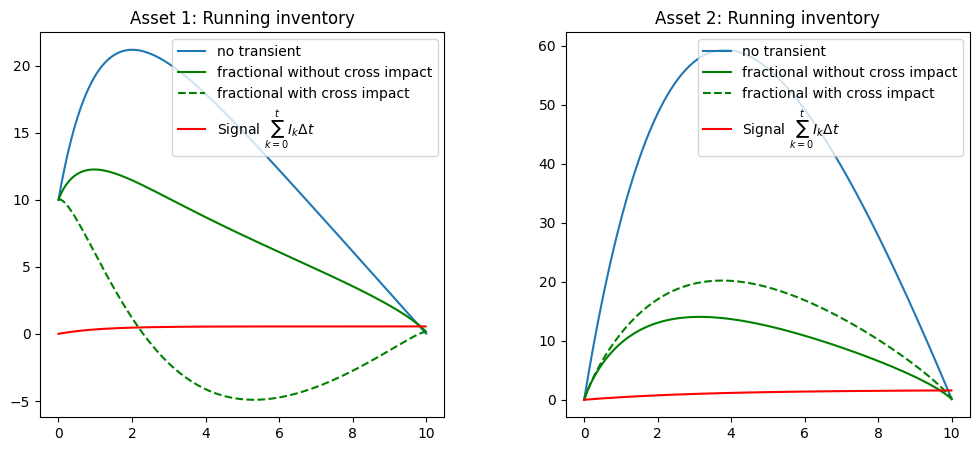

In [8]:
ptf = Portfolio(N=N, T=T, n=n)

_, X_star_zero  = ptf.build_optimal(
                    X0=X0,
                    E_dA=E_dA,
                    Lambda=Lambda,
                    Sigma=Sigma, 
                    gamma=gamma,
                    C=C,
                    varrho=varrho,
                    Pi = Pi,
                    kernel="zero",
                    )


u_star_power, X_star_power  = ptf.build_optimal(
                    X0=X0,
                    E_dA=E_dA,
                    Lambda=Lambda,
                    Sigma=Sigma, 
                    gamma=gamma,
                    C=C,
                    varrho=varrho,
                    Pi = Pi,
                    kernel="power-law",
                    kernel_scale=alpha,
                    )

_, X_star_power_cross  = ptf.build_optimal(
                    X0=X0,
                    E_dA=E_dA,
                    Lambda=Lambda,
                    Sigma=Sigma, 
                    gamma=gamma,
                    C=C_crosseffect,
                    varrho=varrho,
                    Pi = Pi,
                    kernel="power-law",
                    kernel_scale=alpha,
                    )
                    
make_plots2(N,ptf.times, X_star_zero,X_star_power, X_star_power_cross, I_t)
plt.show()

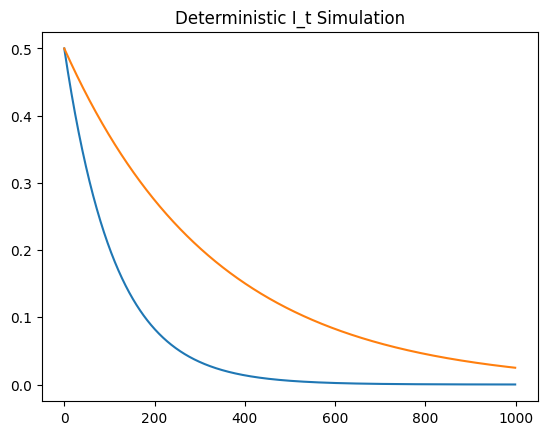

In [9]:
plt.plot(I_t)
plt.title("Deterministic I_t Simulation")
plt.show()

Experiment 4

In [10]:
#Inputs
beta_1, beta_2 = 0.3, 0.9
beta = np.diag([beta_1,beta_2])
I_t = simulate_I_deterministic(n,N,I0, beta, dt)
E_dA = I_t*dt

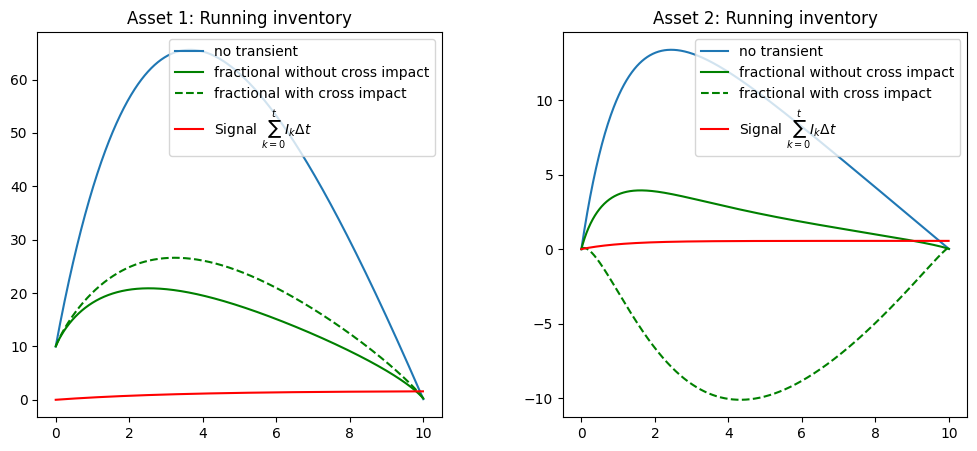

In [11]:
_, X_star_zero  = ptf.build_optimal(
                    X0=X0,
                    E_dA=E_dA,
                    Lambda=Lambda,
                    Sigma=Sigma, 
                    gamma=gamma,
                    C=C,
                    varrho=varrho,
                    Pi = Pi,
                    kernel="zero",
                    )


u_star_power, X_star_power  = ptf.build_optimal(
                    X0=X0,
                    E_dA=E_dA,
                    Lambda=Lambda,
                    Sigma=Sigma, 
                    gamma=gamma,
                    C=C,
                    varrho=varrho,
                    Pi = Pi,
                    kernel="power-law",
                    kernel_scale=alpha,
                    )

_, X_star_power_cross  = ptf.build_optimal(
                    X0=X0,
                    E_dA=E_dA,
                    Lambda=Lambda,
                    Sigma=Sigma, 
                    gamma=gamma,
                    C=C_crosseffect,
                    varrho=varrho,
                    Pi = Pi,
                    kernel="power-law",
                    kernel_scale=alpha,
                    )
                    
make_plots2(N,ptf.times, X_star_zero,X_star_power, X_star_power_cross, I_t)
plt.show()

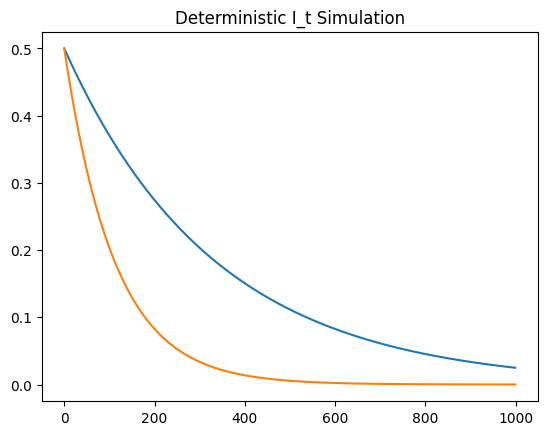

In [12]:
plt.plot(I_t)
plt.title("Deterministic I_t Simulation")
plt.show()

Experiment 5

In [13]:
#Inputs
N=3
X0 = np.array([10,0,0])
varrho = 4
Sigma = np.eye(N)
Lambda = np.diag([0.03,0.03,0.03])
Pi = np.eye(N)
C = np.array([[0.06,0.05,0],[0.05,0.06,0.05],[0,0.05,0.06]])
E_dA = np.zeros((n,N))*dt
ptf = Portfolio(N=N, T=T, n=n)

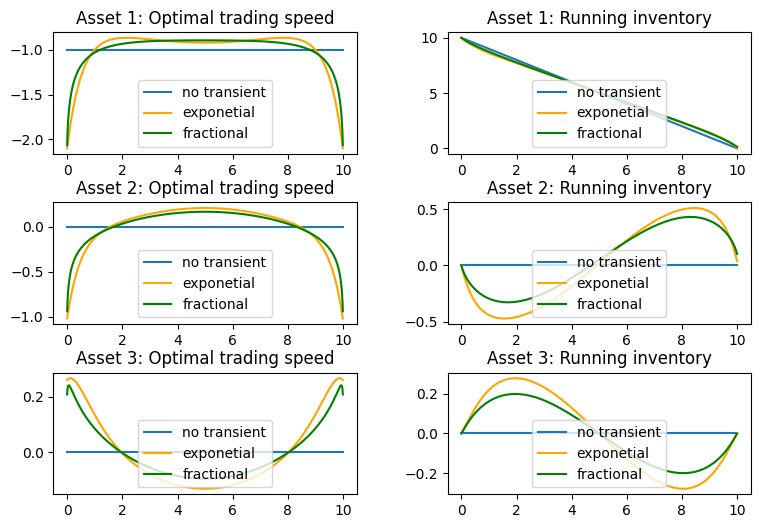

In [14]:
u_star_zero, X_star_zero  = ptf.build_optimal(
                    X0=X0,
                    E_dA=E_dA,
                    Lambda=Lambda,
                    Sigma=Sigma, 
                    gamma=gamma,
                    C=C,
                    varrho=varrho,
                    Pi = Pi,
                    kernel="zero"
                    )

u_star_power, X_star_power  = ptf.build_optimal(
                    X0=X0,
                    E_dA=E_dA,
                    Lambda=Lambda,
                    Sigma=Sigma, 
                    gamma=gamma,
                    C=C,
                    varrho=varrho,
                    Pi = Pi,
                    kernel="power-law",
                    kernel_scale=alpha,
                    )

u_star_expo, X_star_expo  = ptf.build_optimal(
                    X0=X0,
                    E_dA=E_dA,
                    Lambda=Lambda,
                    Sigma=Sigma, 
                    gamma=gamma,
                    C=C,
                    varrho=varrho,
                    Pi = Pi,
                    kernel="exponential",
                    kernel_scale=rho,
                    )

make_plots(N,ptf.times, u_star_zero, u_star_expo, u_star_power, X_star_zero,X_star_expo,X_star_power)
plt.show()

### II. Correlation Influence <br/>


Experiment 6

In [15]:
# Inputs
T=2.5
dt = T/n
N=2
X0 = np.array([10,10])
Lambda = np.array([[0.03,0],[0,0.1]])
gamma = 0.3
Sigma_uncorrelated = 0.2*np.eye(N)
Sigma_correlated = 0.2*np.ones((N,N))


#Need to clarrify 
I_t = simulate_I_deterministic(n, N, I0, beta, dt)
I_t = np.zeros((n,N))
E_dA = I_t*dt
C = np.diag([0.06,0.06])
Pi = np.eye(N)

ptf = Portfolio(N=N, T=T, n=n)

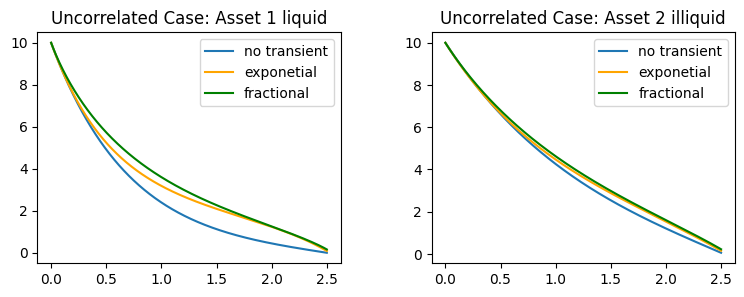

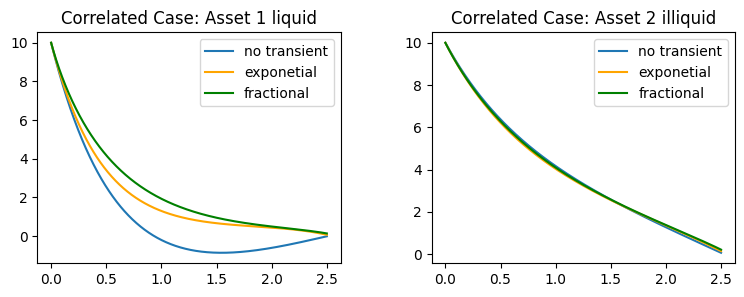

In [16]:
u_star_zero, X_star_zero  = ptf.build_optimal(
                    X0=X0,
                    E_dA=E_dA,
                    Lambda=Lambda,
                    Sigma=Sigma_uncorrelated, 
                    gamma=gamma,
                    C=C,
                    varrho=varrho,
                    Pi = Pi,
                    kernel="zero",
                    )

u_star_power, X_star_power  = ptf.build_optimal(
                    X0=X0,
                    E_dA=E_dA,
                    Lambda=Lambda,
                    Sigma=Sigma_uncorrelated, 
                    gamma=gamma,
                    C=C,
                    varrho=varrho,
                    Pi = Pi,
                    kernel="power-law",
                    kernel_scale=alpha,
                    )

u_star_expo, X_star_expo  = ptf.build_optimal(
                    X0=X0,
                    E_dA=E_dA,
                    Lambda=Lambda,
                    Sigma=Sigma_uncorrelated, 
                    gamma=gamma,
                    C=C,
                    varrho=varrho,
                    Pi = Pi,
                    kernel="exponential",
                    kernel_scale=rho,
                    )

fig_uncorrelated, ax_uncorrelated = make_plots(N,ptf.times, u_star_zero, u_star_expo, u_star_power, X_star_zero,X_star_expo,X_star_power, 
figsize=(9,3), loc="upper right", how="inventory")

u_star_zero, X_star_zero  = ptf.build_optimal(
                    X0=X0,
                    E_dA=E_dA,
                    Lambda=Lambda,
                    Sigma=Sigma_correlated, 
                    gamma=gamma,
                    C=C,
                    varrho=varrho,
                    Pi = Pi,
                    kernel="zero",
                    )

u_star_power, X_star_power  = ptf.build_optimal(
                    X0=X0,
                    E_dA=E_dA,
                    Lambda=Lambda,
                    Sigma=Sigma_correlated, 
                    gamma=gamma,
                    C=C,
                    varrho=varrho,
                    Pi = Pi,
                    kernel="power-law",
                    kernel_scale=alpha,
                    )

u_star_expo, X_star_expo  = ptf.build_optimal(
                    X0=X0,
                    E_dA=E_dA,
                    Lambda=Lambda,
                    Sigma=Sigma_correlated, 
                    gamma=gamma,
                    C=C,
                    varrho=varrho,
                    Pi = Pi,
                    kernel="exponential",
                    kernel_scale=rho,
                    )

fig_correlated, ax_correlated = make_plots(N,ptf.times, u_star_zero, u_star_expo, u_star_power, X_star_zero,X_star_expo,X_star_power, 
figsize=(9,3), loc="upper right", how="inventory")

ax_correlated[0].set_title("Correlated Case: Asset 1 liquid")
ax_correlated[1].set_title("Correlated Case: Asset 2 illiquid")
ax_uncorrelated[0].set_title("Uncorrelated Case: Asset 1 liquid")
ax_uncorrelated[1].set_title("Uncorrelated Case: Asset 2 illiquid")
plt.show()

Experiment 7

In [17]:
# Inputs
varrho = 0
gamma = 5
T=5
N=2
X0 = np.array([7.5,-7.5])
Lambda = np.array([[0.03,0],[0,0.03]])
Lambda_bis = np.array([[0.001,0],[0,0.001]])
Sigma= np.diag([0.04,0.05])
I_0 = np.array([0.01, -0.01])
beta_1, beta_2 = 0.05, 0.3
beta = np.diag([beta_1,beta_2])
I_t = simulate_I_deterministic(n,N,I0, beta, dt)
E_dA = I_t*dt
C = np.diag([0.06,0.06])

ptf = Portfolio(N=N, T=T, n=n)

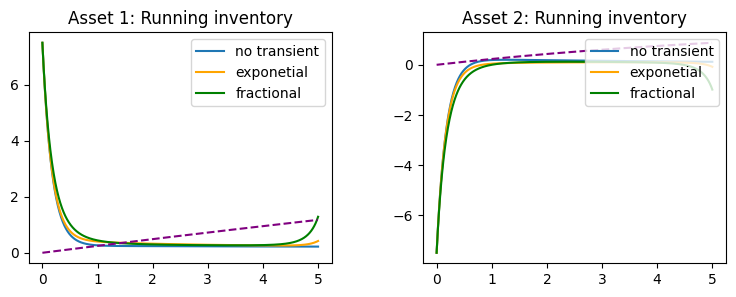

In [18]:
X_star_markowitz = ptf.build_Markowitz_optimal(Sigma, I_t, gamma)

u_star_zero, X_star_zero  = ptf.build_optimal(
                    X0=X0,
                    E_dA=E_dA,
                    Lambda=Lambda,
                    Sigma=Sigma_uncorrelated, 
                    gamma=gamma,
                    C=C,
                    varrho=varrho,
                    Pi = Pi,
                    kernel="zero",
                    )

u_star_power, X_star_power  = ptf.build_optimal(
                    X0=X0,
                    E_dA=E_dA,
                    Lambda=Lambda,
                    Sigma=Sigma_uncorrelated, 
                    gamma=gamma,
                    C=C,
                    varrho=varrho,
                    Pi = Pi,
                    kernel="power-law",
                    kernel_scale=alpha,
                    )

u_star_expo, X_star_expo  = ptf.build_optimal(
                    X0=X0,
                    E_dA=E_dA,
                    Lambda=Lambda,
                    Sigma=Sigma_uncorrelated, 
                    gamma=gamma,
                    C=C,
                    varrho=varrho,
                    Pi = Pi,
                    kernel="exponential",
                    kernel_scale=rho,
                    )

fig, ax = make_plots(N,ptf.times, u_star_zero, u_star_expo, u_star_power, X_star_zero,X_star_expo,X_star_power, 
figsize=(9,3), loc="upper right", how="inventory")
ax[0].plot(ptf.times[:-1:], np.cumsum(I_t*dt,axis=0)[:,0], '--', label=r'Signal $\sum_{k=0}^{t}I_k \Delta t$', color='purple')

ax[1].plot(ptf.times[:-1:], np.cumsum(I_t*dt,axis=0)[:,1], '--', label=r'Signal $\sum_{k=0}^{t}I_k \Delta t$', color='purple')
#ax[0].plot(ptf.times[:-1:], X_star_markowitz[:,0], label='Markowitz', color='red')
plt.show()
